<a href="https://colab.research.google.com/github/AnabelleS18/AE352-final-group-project/blob/main/AE352code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

m = 1.540
g = 9.81
L = 0.250
k = L / np.sqrt(2)

T_hover = m * g
T_rotor = T_hover / 4

In [ ]:

def translational_acceleration(phi, theta, psi, T, m, g):

    x_ddot = (T/m) * (
        np.cos(psi)*np.sin(theta)*np.cos(phi)
        + np.sin(psi)*np.sin(phi)
    )

    y_ddot = (T/m) * (
        np.sin(psi)*np.sin(theta)*np.cos(phi)
        - np.cos(psi)*np.sin(phi)
    )

    z_ddot = (T/m)*np.cos(theta)*np.cos(phi) - g

    return np.array([x_ddot, y_ddot, z_ddot])


In [ ]:

rpm_hover = 5380
w_hover = rpm_hover * 2*np.pi / 60


I = np.array([0.020, 0.020, 0.040])
Jr = 1.0e-4

cT = (m*g/4) / w_hover**2
cQ = 0.052 / w_hover**2


spin_reaction = np.array([-1, 1, -1, 1])

tau_hover = cQ * w_hover**2


In [ ]:

def drone_eom(t, X, U):
    x, y, z = X[0:3]
    vx, vy, vz = X[3:6]
    phi, theta, psi = X[6:9]
    p, q, r = X[9:12]
    w1, w2, w3, w4 = X[12:16]

    T1 = cT * w1**2
    T2 = cT * w2**2
    T3 = cT * w3**2
    T4 = cT * w4**2

    T = T1 + T2 + T3 + T4


    ax = (T/m) * (
        np.cos(psi)*np.sin(theta)*np.cos(phi)
        + np.sin(psi)*np.sin(phi))

    ay = (T/m) * (
        np.sin(psi)*np.sin(theta)*np.cos(phi)
        - np.cos(psi)*np.sin(phi))

    az = (T/m)*np.cos(theta)*np.cos(phi) - g


    tau_m1, tau_m2, tau_m3, tau_m4 = U


    tau_x = k * (T1 - T2 - T3 + T4)
    tau_y = k * (-T1 - T2 + T3 + T4)
    tau_z = -tau_m1 + tau_m2 - tau_m3 + tau_m4

    Ixx, Iyy, Izz = I

    p_dot = ((Iyy - Izz)*q*r + tau_x) / Ixx
    q_dot = ((Izz - Ixx)*p*r + tau_y) / Iyy
    r_dot = ((Ixx - Iyy)*p*q + tau_z) / Izz


    phi_dot = (p
        + q*np.sin(phi)*np.tan(theta)
        + r*np.cos(phi)*np.tan(theta))

    theta_dot = q*np.cos(phi) - r*np.sin(phi)

    psi_dot = (
        q*np.sin(phi) + r*np.cos(phi)
    ) / np.cos(theta)


    w1_dot = (tau_m1 - cQ*w1**2) / Jr
    w2_dot = (tau_m2 - cQ*w2**2) / Jr
    w3_dot = (tau_m3 - cQ*w3**2) / Jr
    w4_dot = (tau_m4 - cQ*w4**2) / Jr


    return np.array([
        vx, vy, vz,
        ax, ay, az,
        phi_dot, theta_dot, psi_dot,
        p_dot, q_dot, r_dot,
        w1_dot, w2_dot, w3_dot, w4_dot])


In [ ]:

X0 = np.array([
    0.0, 0.0, 1,
    0.0, 0.0, 0.0,
    0.0, 0.0, 0.0,
    0.0, 0.0, 0.0,
    w_hover, w_hover, w_hover, w_hover])

U = np.array([tau_hover, tau_hover, tau_hover, tau_hover])

In [ ]:
t_span = (0, 120)
t_eval = np.linspace(0, 120, 1201)

sol = solve_ivp(
    lambda t, X: drone_eom(t, X, U),
    t_span,
    X0,
    t_eval=t_eval,
    rtol=1e-9,
    atol=1e-11)

Simulation successful: True
The solver successfully reached the end of the integration interval.


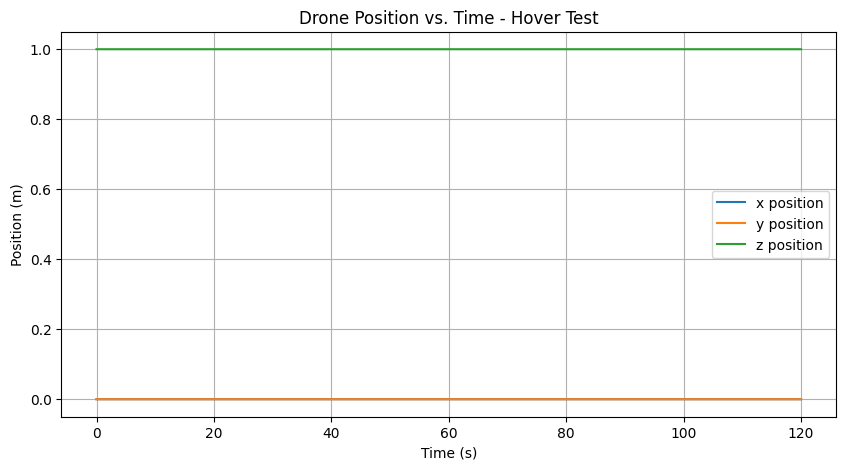

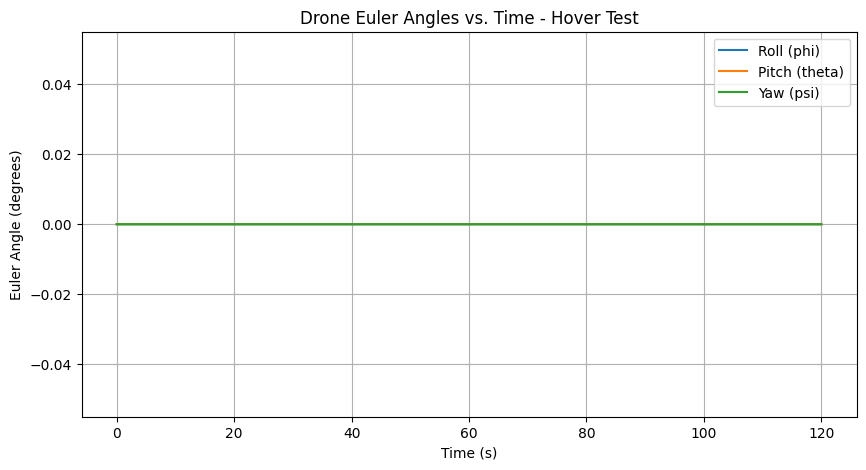

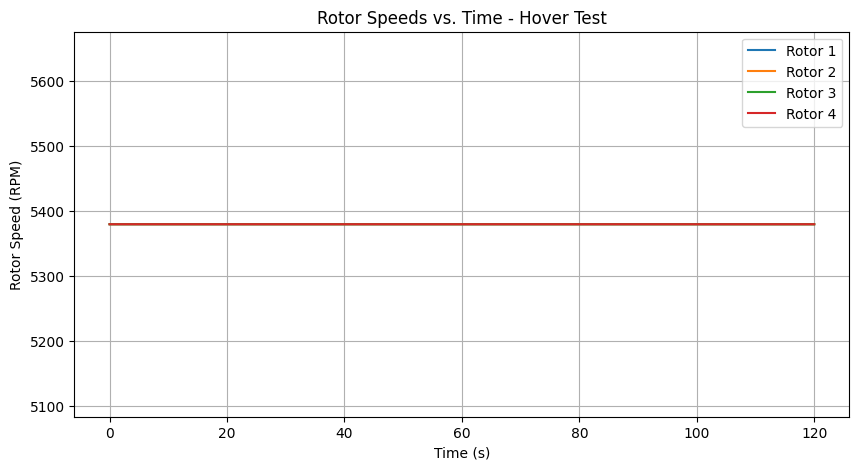

In [ ]:

t = sol.t
x = sol.y[0]
y = sol.y[1]
z = sol.y[2]

vx = sol.y[3]
vy = sol.y[4]
vz = sol.y[5]

phi = sol.y[6]
theta = sol.y[7]
psi = sol.y[8]

w1 = sol.y[12]
w2 = sol.y[13]
w3 = sol.y[14]
w4 = sol.y[15]

#position
plt.figure(figsize=(10, 5))
plt.plot(t, x, label="x")
plt.plot(t, y, label="y")
plt.plot(t, z, label="z")
plt.xlabel("time (s)")
plt.ylabel("position (m)")
plt.title("Position vs. Time - test 1")
plt.legend()
plt.grid()
plt.show()

#eulers angle
plt.figure(figsize=(10, 5))
plt.plot(t, np.degrees(phi), label="roll (phi)")
plt.plot(t, np.degrees(theta), label="pitch (theta)")
plt.plot(t, np.degrees(psi), label="yaw (psi)")
plt.xlabel("time (s)")
plt.ylabel("euler Angle (degrees)")
plt.title("euler angles vs. time - test 1")
plt.legend()
plt.grid()
plt.show()


#motor speed
plt.figure(figsize=(10, 5))
plt.plot(t, w1*60/(2*np.pi), label="Rotor 1")
plt.plot(t, w2*60/(2*np.pi), label="Rotor 2")
plt.plot(t, w3*60/(2*np.pi), label="Rotor 3")
plt.plot(t, w4*60/(2*np.pi), label="Rotor 4")
plt.xlabel("Time (s)")
plt.ylabel("Rotor Speed (RPM)")
plt.title("Rotor Speeds vs. Time - test 1")
plt.legend()
plt.grid()
plt.show()


In [ ]:

#test 2

radius = 2.0
speed = 0.5
z_target = 1.0
duration = 60.0

Omega = speed / radius
tilt = np.radians(0.73)
theta_circle = theta_circle = -np.arctan((speed**2 / radius) / g)
p_circle = -Omega * np.sin(theta_circle)
q_circle = 0.0
r_circle = Omega * np.cos(theta_circle)


T_circle = m*g / np.cos(theta_circle)

Ixx, Iyy, Izz = I

tau_y_circle = (Ixx - Izz)*p_circle*r_circle
T1 = T_circle/4 - tau_y_circle/(4*k)
T2 = T1
T3 = T_circle/4 + tau_y_circle/(4*k)
T4 = T3
#assert min(T1, T2, T3, T4) > 0

w1_circle = np.sqrt(T1/cT)
w2_circle = np.sqrt(T2/cT)
w3_circle = np.sqrt(T3/cT)
w4_circle = np.sqrt(T4/cT)

U_circle = np.array([
    cQ*w1_circle**2,
    cQ*w2_circle**2,
    cQ*w3_circle**2,
    cQ*w4_circle**2])

In [ ]:
X0_circle = np.array([
    radius, 0, z_target,
    0, speed, 0,
    0, theta_circle, 0,
    p_circle, q_circle, r_circle,
    w1_circle, w2_circle,
    w3_circle, w4_circle
], dtype=float)

t_span_circle = (0, duration)
t_eval_circle = np.linspace(0, duration, 1201)

sol_circle = solve_ivp(
    lambda t, X: drone_eom(t, X, U_circle),
    t_span_circle,
    X0_circle,
    t_eval=t_eval_circle,
    rtol=1e-9,
    atol=1e-11)

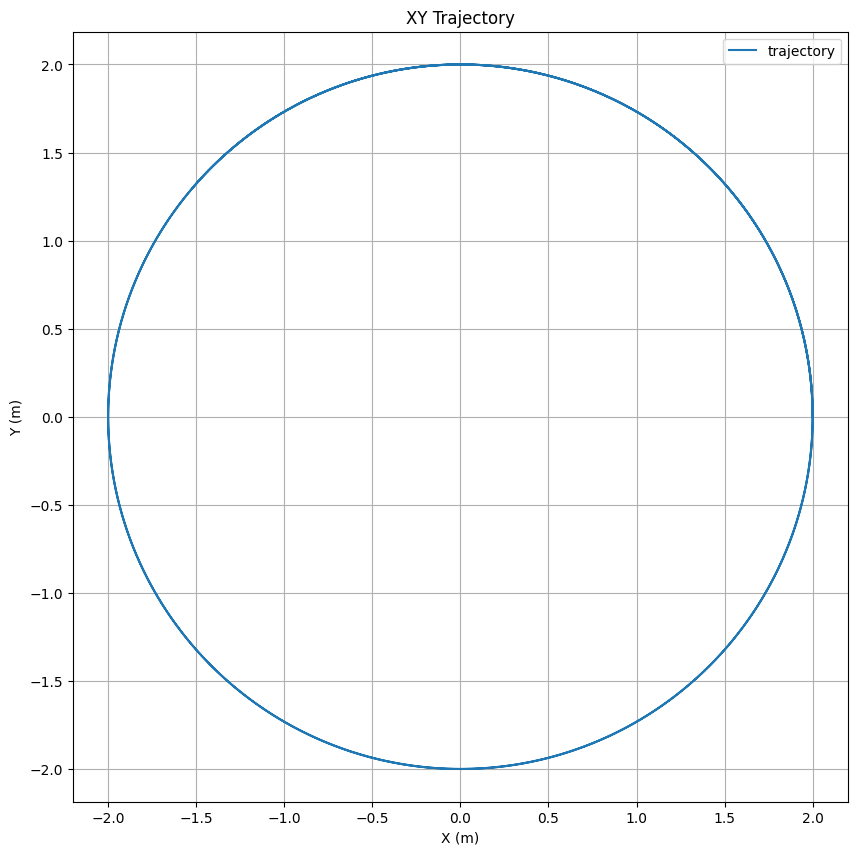

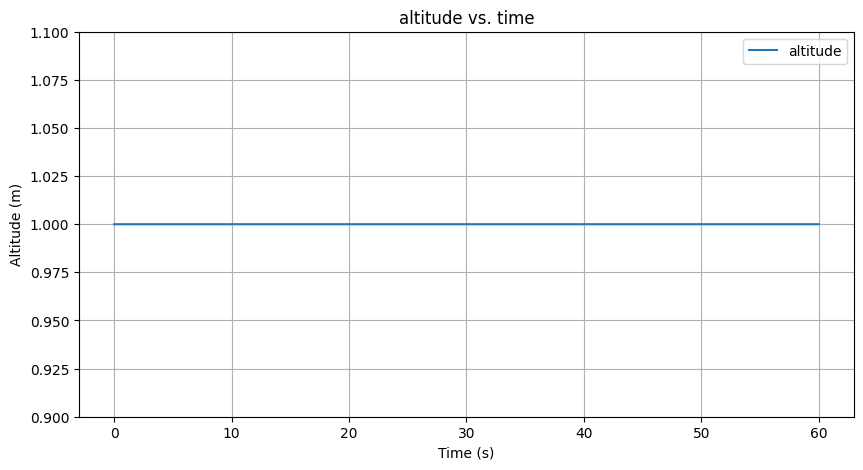

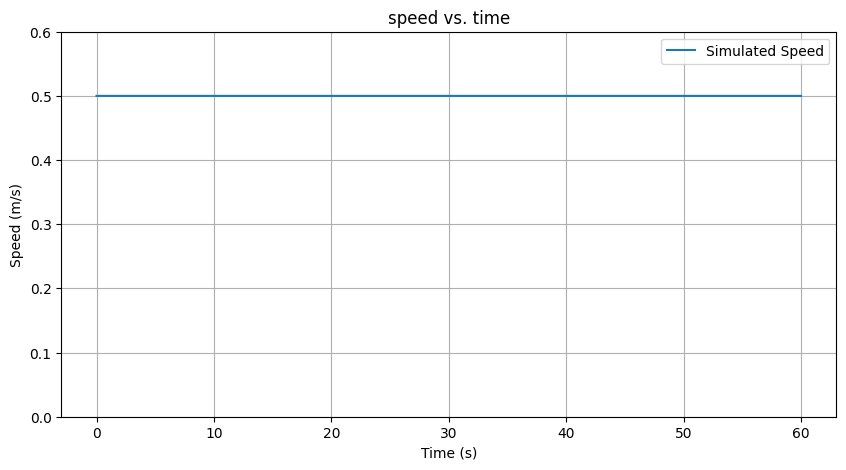

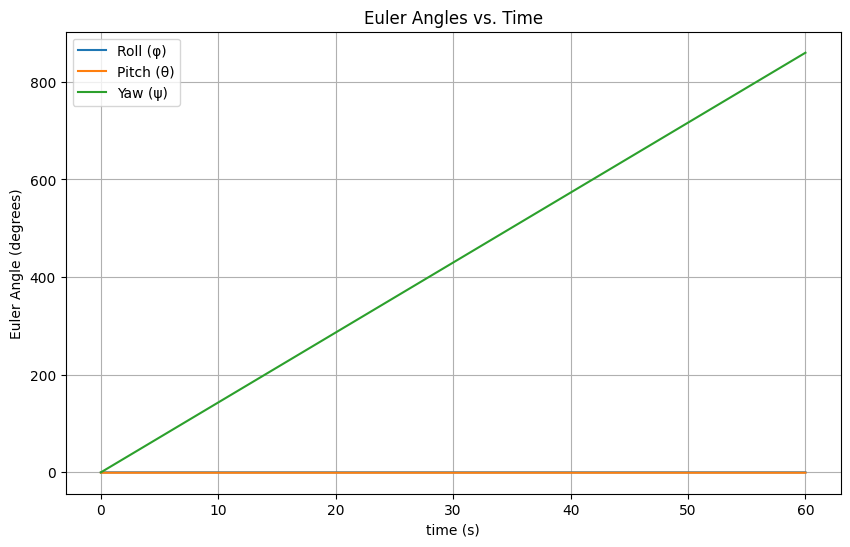

In [ ]:
#y/x trajectory
x = sol_circle.y[0]
y = sol_circle.y[1]
z = sol_circle.y[2]
plt.figure(figsize=(10, 10))
plt.plot(x, y, label="trajectory")
plt.xlabel("X (m)")
plt.ylabel("Y (m)")
plt.title("XY Trajectory")
plt.axis("equal")
plt.legend()
plt.grid()
plt.show()


#altitude
plt.figure(figsize=(10, 5))
plt.plot(sol_circle.t, sol_circle.y[2],
         label="altitude")
plt.xlabel("Time (s)")
plt.ylabel("Altitude (m)")
plt.title("altitude vs. time")
plt.ylim(0.9, 1.1)
plt.grid()
plt.legend()
plt.show()


#speed graph
vx = sol_circle.y[3]
vy = sol_circle.y[4]
vz = sol_circle.y[5]
speed_actual = np.sqrt(vx**2 + vy**2 + vz**2)
plt.figure(figsize=(10, 5))
plt.plot(sol_circle.t, speed_actual,
         label="Simulated Speed")
plt.xlabel("Time (s)")
plt.ylabel("Speed (m/s)")
plt.title("speed vs. time")
plt.ylim(0, 0.6)
plt.ticklabel_format(axis="y", style="plain")
plt.legend()
plt.grid()
plt.show()


# Eulars Angles
phi = sol_circle.y[6]
theta = sol_circle.y[7]
psi = sol_circle.y[8]
phi_deg = np.degrees(phi)
theta_deg = np.degrees(theta)
psi_deg = np.degrees(psi)
plt.figure(figsize=(10, 6))
plt.plot(sol_circle.t, phi_deg, label="Roll (φ)")
plt.plot(sol_circle.t, theta_deg, label="Pitch (θ)")
plt.plot(sol_circle.t, psi_deg, label="Yaw (ψ)")
plt.xlabel("time (s)")
plt.ylabel("Euler Angle (degrees)")
plt.title("Euler Angles vs. Time")
plt.legend()
plt.grid()
plt.show()



In [ ]:

#Test 3

z_target = 1.0
distance_1 = 5.0
distance_2 = 5.0
speed_target = 1.0
yaw_target = np.radians(90)
landing_speed_max = 0.01


In [ ]:
X0_test3 = np.array([
    0, 0, 0,
    0, 0, 0,
    0, 0, 0,
    0, 0, 0,
    w_hover, w_hover,
    w_hover, w_hover
], dtype=float)


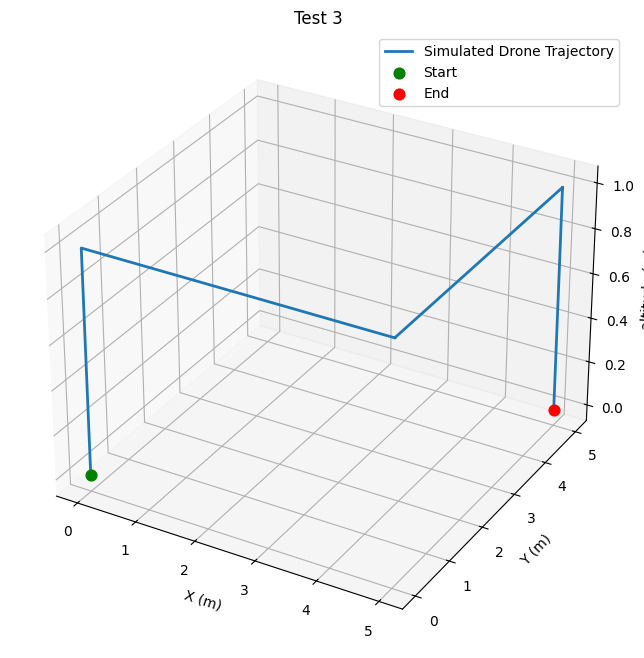

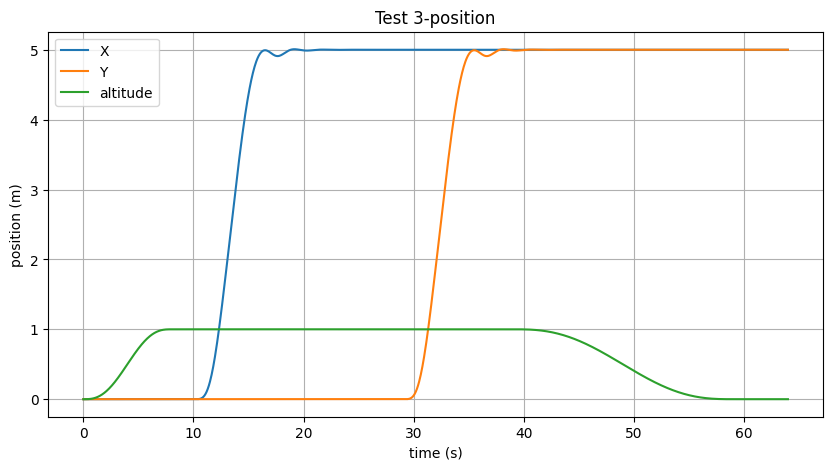

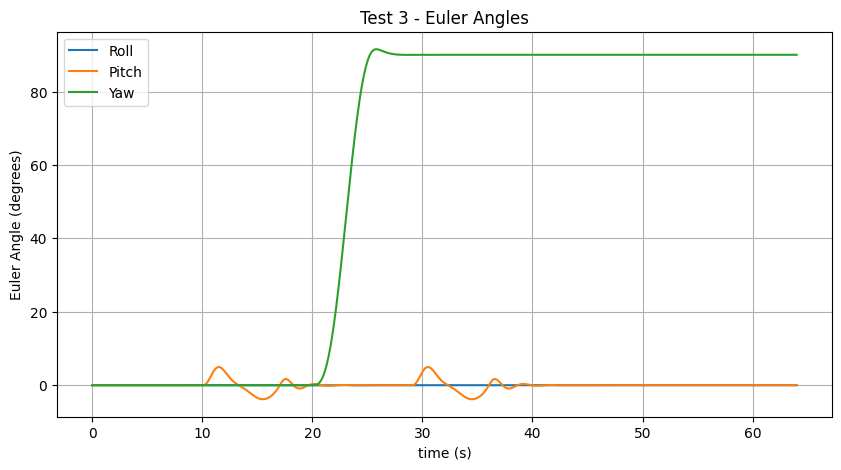

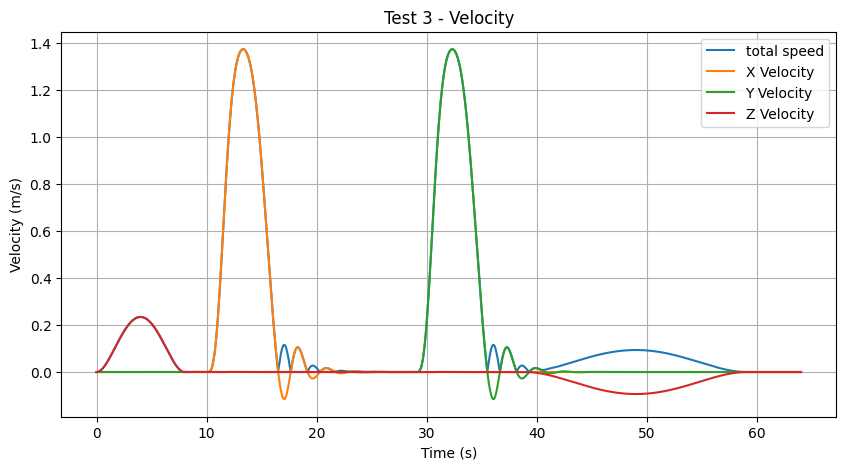

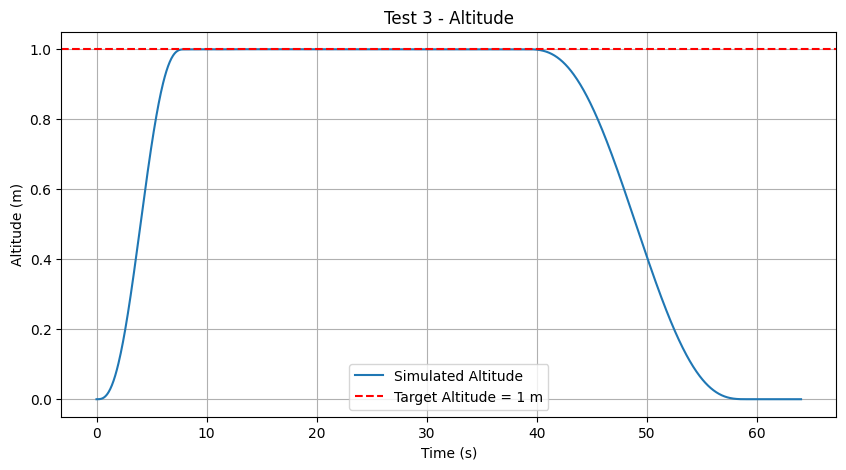

In [ ]:
t_takeoff = (0.0, 8.0)
t_forward1 = (10.0, 17.0)
t_turn = (20.0, 26.0)
t_forward2 = (29.0, 36.0)
t_landing = (39.0, 59.0)

duration_test3 = 64.0

def smooth_motion(t, t0, t1):
    u = np.clip((t - t0)/(t1 - t0), 0, 1)
    s = 10*u**3 - 15*u**4 + 6*u**5
    sd = (
        30*u**2 - 60*u**3 + 30*u**4
    )/(t1 - t0)
    sdd = (
        60*u - 180*u**2 + 120*u**3
    )/(t1 - t0)**2
    return s, sd, sdd

def test3_reference(t):
    sz, vzd, azd = smooth_motion(t, *t_takeoff)
    sx, vxd, axd = smooth_motion(t, *t_forward1)
    syaw, yaw_rate, _ = smooth_motion(t, *t_turn)
    sy, vyd, ayd = smooth_motion(t, *t_forward2)
    sl, vl, al = smooth_motion(t, *t_landing)

    position_d = np.array([
        distance_1*sx,
        distance_2*sy,
        z_target*(sz - sl)
    ])

    velocity_d = np.array([
        distance_1*vxd,
        distance_2*vyd,
        z_target*(vzd - vl)
    ])

    acceleration_d = np.array([
        distance_1*axd,
        distance_2*ayd,
        z_target*(azd - al)
    ])

    psi_d = yaw_target*syaw
    psi_dot_d = yaw_target*yaw_rate

    return (
        position_d,
        velocity_d,
        acceleration_d,
        psi_d,
        psi_dot_d
    )

def test3_motor_torques(t, X):
    position = X[0:3]
    velocity = X[3:6]

    phi, theta, psi = X[6:9]
    p, q, r = X[9:12]

    w = X[12:16]
    pos_d, vel_d, acc_d, psi_d, psi_dot_d = (
        test3_reference(t)
    )
    Kp_pos = np.array([1.6, 1.6, 2.8])
    Kd_pos = np.array([2.3, 2.3, 3.2])

    a_cmd = (
        acc_d
        + Kp_pos*(pos_d - position)
        + Kd_pos*(vel_d - velocity)
    )
    a_cmd = np.clip(
        a_cmd,
        [-3.0, -3.0, -3.0],
        [3.0, 3.0, 3.0]
    )

    theta_d = np.clip(
        (a_cmd[0]*np.cos(psi)
         + a_cmd[1]*np.sin(psi))/g,
        -0.25, 0.25
    )

    phi_d = np.clip(
        (a_cmd[0]*np.sin(psi)
         - a_cmd[1]*np.cos(psi))/g,
        -0.25, 0.25
    )

    T = m*(g + a_cmd[2])

    T = T / max(
        0.8,
        np.cos(phi)*np.cos(theta)
    )

    T = np.clip(T, 0.3*m*g, 1.7*m*g)
    Ixx, Iyy, Izz = I
    tau_x = Ixx*(
        18*(phi_d - phi) - 7*p
    )
    tau_y = Iyy*(
        18*(theta_d - theta) - 7*q
    )
    yaw_error = (
        psi_d - psi + np.pi
    ) % (2*np.pi) - np.pi

    tau_z = Izz*(
        8*yaw_error + 3*(psi_dot_d - r)
    )

    tau_x = np.clip(tau_x, -0.25, 0.25)
    tau_y = np.clip(tau_y, -0.25, 0.25)
    tau_z = np.clip(tau_z, -0.07, 0.07)

    B = np.array([
        [1, 1, 1, 1],
        [k, -k, -k, k],
        [-k, -k, k, k],
        [-cQ/cT, cQ/cT, -cQ/cT, cQ/cT]
    ])

    thrusts = np.linalg.solve(
        B,
        np.array([T, tau_x, tau_y, tau_z])
    )

    thrusts = np.clip(thrusts, 0.05, 9.0)
    w_target = np.sqrt(thrusts/cT)
    U = (
        cQ*w**2
        + Jr*35*(w_target - w))
    return U

t_eval_test3 = np.linspace(
    0, duration_test3, 1281)

sol_test3 = solve_ivp(
    lambda t, X: drone_eom(
        t, X, test3_motor_torques(t, X)
    ),
    (0, duration_test3),
    X0_test3,
    t_eval=t_eval_test3,
    rtol=1e-7,
    atol=1e-9,
    max_step=0.02)

t3 = sol_test3.t

x3 = sol_test3.y[0]
y3 = sol_test3.y[1]
z3 = sol_test3.y[2]

vx3 = sol_test3.y[3]
vy3 = sol_test3.y[4]
vz3 = sol_test3.y[5]

phi3 = np.degrees(sol_test3.y[6])
theta3 = np.degrees(sol_test3.y[7])
psi3 = np.degrees(sol_test3.y[8])

speed3 = np.sqrt(
    vx3**2 + vy3**2 + vz3**2)

#3d trajectory
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
ax.plot(
    x3, y3, z3,
    label="Simulated Drone Trajectory",
    linewidth=2)
ax.scatter(
    x3[0], y3[0], z3[0],
    color="green", s=60, label="Start")
ax.scatter(
    x3[-1], y3[-1], z3[-1],
    color="red", s=60, label="End")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.set_zlabel("altitude (m)")
ax.set_title("Test 3")
ax.legend()
plt.show()

#position
plt.figure(figsize=(10, 5))
plt.plot(t3, x3, label="X")
plt.plot(t3, y3, label="Y")
plt.plot(t3, z3, label="altitude")
plt.xlabel("time (s)")
plt.ylabel("position (m)")
plt.title("Test 3-position")
plt.legend()
plt.grid()
plt.show()

#eulers angle
plt.figure(figsize=(10, 5))
plt.plot(t3, phi3, label="Roll")
plt.plot(t3, theta3, label="Pitch")
plt.plot(t3, psi3, label="Yaw")
plt.xlabel("time (s)")
plt.ylabel("Euler Angle (degrees)")
plt.title("Test 3 - Euler Angles")
plt.legend()
plt.grid()
plt.show()

#speed
plt.figure(figsize=(10, 5))
plt.plot(t3, speed3, label="total speed")
plt.plot(t3, vx3, label="X Velocity")
plt.plot(t3, vy3, label="Y Velocity")
plt.plot(t3, vz3, label="Z Velocity")
plt.xlabel("Time (s)")
plt.ylabel("Velocity (m/s)")
plt.title("Test 3 - Velocity")
plt.legend()
plt.grid()
plt.show()

#altitude
plt.figure(figsize=(10, 5))
plt.plot(t3, z3, label="Simulated Altitude")
plt.axhline(
    z_target,
    color="red",
    linestyle="--",
    label="Target Altitude = 1 m")
plt.xlabel("Time (s)")
plt.ylabel("Altitude (m)")
plt.title("Test 3 - Altitude")
plt.legend()
plt.grid()
plt.show()


